# Document Classification: Predicting Email Spam with Spambase

Anthony Josue Roman
DATA 620  
Week Ten Assignment

## Introduction

If an email classification error occurs, depending on whether the classification error occurred in the prediction of spam or non-spam, either an unsolicited message is incorrectly added to the inbox or an important message lands in the spam mailbox. The latter might lead to missing a deadline. In this study, we analyze both types of errors in classification of emails as spam or ham.

The Spambase dataset provided by the UCI Machine Learning Repository consists of 4,601 emails labeled according to their true class. There are 57 features per each example describing word frequency, character frequency and capitals frequency. This set of features allows us to analyze which characteristics help classify the email correctly.

## Research questions

1. In what ways does the logistic regression/random forest model compare to a basic model that simply assumes that all emails are legitimate?
2. How well does the random forest classifier do when it uses only word counts, only character and capitalization information, or all 57 attributes at once?
3. With a more stringent criterion for classifying an email, how many legitimate messages remain in the inbox, and how much additional spam is let through?

## Understanding the Spambase Dataset

Each row corresponds to an individual email. The first 57 attributes contain information about the email, while the last attribute holds the true label of the email, which is `1` for spam emails and `0` for valid emails. When training the model, it utilizes the label in order to learn from examples. On the other hand, when testing the model, it predicts the label based on the 57 features.

| Feature group | Columns | How to interpret a value |
|---|---:|---|
| Word frequencies | 48 | A `word_freq_free` value of `2.0` means that 2% of the words in the email are “free.” |
| Character frequencies | 6 | A `char_freq_!` value of `0.5` means that 0.5% of the characters are exclamation marks. |
| Capital-letter runs | 3 | A `capital_run_length_longest` value of `12` means the longest uninterrupted sequence of capital letters contains 12 letters. |

Percentage represents features of words and characters while Length and Count represent features of capitalization. The significance of this is that when `2` appears in a specific column, it will have a different meaning from when it appears in another column. Also, there is a way of comparing word choice information to punctuation and capitalization information.

**Source:** [UCI Machine Learning Repository, Spambase](https://archive.ics.uci.edu/dataset/94/spambase)

In [ ]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import pandas as pd

local_archive = Path("spambase.zip")
url = "https://archive.ics.uci.edu/static/public/94/spambase.zip"

if local_archive.exists():
    archive = local_archive
else:
    with urlopen(url, timeout=30) as response:
        archive = BytesIO(response.read())

with ZipFile(archive) as files:
    definitions = files.read("spambase.names").decode().splitlines()
    prefixes = ("word_freq_", "char_freq_", "capital_run_length_")
    feature_names = [
        line.split(":", 1)[0].strip()
        for line in definitions
        if line.startswith(prefixes)
    ]

    with files.open("spambase.data") as data_file:
        emails = pd.read_csv(data_file, header=None)

assert len(feature_names) == 57, "Expected 57 feature names."
assert emails.shape == (4601, 58), "Expected 4,601 rows and 58 columns."
emails.columns = feature_names + ["spam"]

print(f"Emails: {len(emails):,}")
print(f"Predictor columns: {len(feature_names)}")
print(f"Total columns, including the label: {emails.shape[1]}")

emails[["word_freq_free", "char_freq_!", "capital_run_length_longest", "spam"]].head()

Emails: 4,601
Predictor columns: 57
Total columns, including the label: 58


,word_freq_free,char_freq_!,capital_run_length_longest,spam
0,0.32,0.778,61,1
1,0.14,0.372,101,1
2,0.06,0.276,485,1
3,0.31,0.137,40,1
4,0.31,0.135,40,1


In [5]:
print("Missing values across all columns:", emails.isna().sum().sum())
assert set(emails["spam"].unique()) == {0, 1}, "Expected labels 0 and 1."

profiles = emails[feature_names]
print("Distinct feature profiles:", f"{len(profiles.drop_duplicates()):,}")
print("Rows repeating an earlier profile:", f"{profiles.duplicated().sum():,}")

counts = emails["spam"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "Emails": counts,
    "Percent": (100 * counts / len(emails)).round(1)
})
class_summary.index = ["Ham (0)", "Spam (1)"]
class_summary

Missing values across all columns: 0
Distinct feature profiles: 4,207
Rows repeating an earlier profile: 394


,Emails,Percent
Ham (0),2788,60.6
Spam (1),1813,39.4


## Data Quality and the Train-Test Split

All 4,601 emails have values in all 57 predictors and the class label. There are 2,788 non-spam emails in this dataset (60.6%), and there are 1,813 spam emails (39.4%). If a classifier predicted all emails as non-spam emails, its accuracy would be 60.6%, and it wouldn't detect any spam. Therefore, the inclusion of the spam precision and recall measures in the analysis is justified by this baseline.

There are 4,207 unique profiles in the 4,601 emails. In 394 cases, all 57 predictor values coincide with another earlier row in the dataset. Since Spambase includes only measurements, not the original text of the email, this coincidence does not mean that these messages are exactly the same.

In order to evaluate how the model performs on new emails, I will keep the emails with coinciding profiles together and will separate approximately 20% of emails into a test dataset. The proportion of spam and non-spam emails in these datasets will be similar.

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

X = emails[feature_names]
y = emails["spam"]

groups = X.groupby(feature_names, sort=False).ngroup()

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

shared_profiles = set(train_groups).intersection(test_groups)
assert len(shared_profiles) == 0, "A feature profile appears in both sets."
assert len(X_train) + len(X_test) == len(emails)
print(f"Feature profiles shared between training and testing: {len(shared_profiles)}")

split_summary = pd.DataFrame({
    "Emails": [len(y_train), len(y_test)],
    "Ham": [y_train.eq(0).sum(), y_test.eq(0).sum()],
    "Spam": [y_train.eq(1).sum(), y_test.eq(1).sum()],
    "Spam (%)": [100 * y_train.mean(), 100 * y_test.mean()]
}, index=["Training", "Testing"])

split_summary.round(1)

Feature profiles shared between training and testing: 0


,Emails,Ham,Spam,Spam (%)
Training,3680,2230,1450,39.4
Testing,921,558,363,39.4


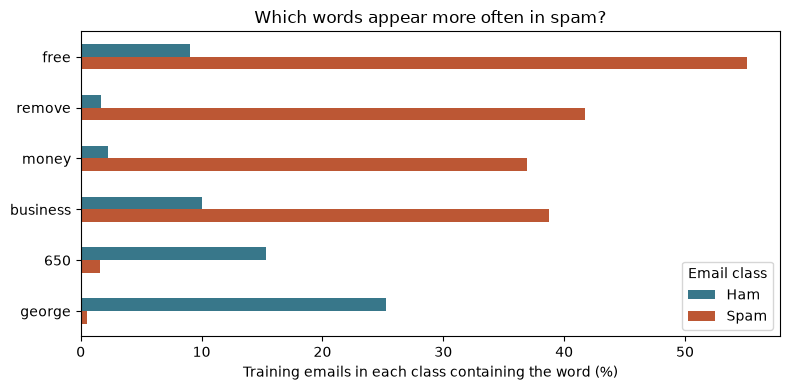

spam,Ham,Spam,Gap (percentage points)
free,9.1,55.1,46.0
remove,1.7,41.7,40.1
money,2.2,37.0,34.7
business,10.0,38.8,28.8
650,15.3,1.6,-13.7
george,25.3,0.6,-24.7


In [7]:
import matplotlib.pyplot as plt

words = ["free", "money", "remove", "business", "george", "650"]
word_columns = [f"word_freq_{word}" for word in words]

word_present = X_train[word_columns].gt(0)
word_present.columns = words

word_rates = word_present.groupby(y_train).mean().T.mul(100)
word_rates = word_rates.rename(columns={0: "Ham", 1: "Spam"})
word_rates["Gap (percentage points)"] = word_rates["Spam"] - word_rates["Ham"]
word_rates = word_rates.sort_values("Gap (percentage points)", ascending=False)

ax = word_rates[["Ham", "Spam"]].plot.barh(
    figsize=(8, 4),
    color=["#38778a", "#bc5734"]
)
ax.invert_yaxis()
ax.set(
    title="Which words appear more often in spam?",
    xlabel="Training emails in each class containing the word (%)",
    ylabel=""
)
ax.legend(title="Email class")
plt.tight_layout()
plt.show()

word_rates.round(1)

### What does word choice tell us about spam?

Of the six keywords, the term "free" had the largest difference. It was found in 55.1 percent of spam messages and 9.1 percent of legitimate emails, resulting in a 46.0 percent difference. As such, an email filter based on "free" would detect more than half the spam emails, but miss 44.9 percent of them while wrongly flagging one out of every eleven legitimate emails.

"Remove" represents an opposite trade-off in performance. An email filter using "remove" would mark only 1.7 percent of the legitimate emails, but 41.7 percent of the spam. This was not the case for "george," which occurred in 25.3 percent of the legitimate emails and 0.6 percent of the spam emails. A name useful for filtering legitimate emails in this dataset might be worthless in someone else's emails.

This brings the need for comparison between models that use multiple indicators into focus. The next phase is to investigate the punctuation and capitalization in the data set.

In [8]:
symbol_columns = {
    "char_freq_!": "Exclamation mark (!)",
    "char_freq_$": "Dollar sign ($)",
    "char_freq_#": "Number sign (#)"
}

symbol_present = X_train[list(symbol_columns)].gt(0)
symbol_rates = symbol_present.groupby(y_train).mean().T.mul(100)
symbol_rates = symbol_rates.rename(index=symbol_columns, columns={0: "Ham", 1: "Spam"})
symbol_rates["Gap (percentage points)"] = symbol_rates["Spam"] - symbol_rates["Ham"]

print("Training emails containing each symbol (%)")
display(symbol_rates.round(1))

capital_runs = X_train["capital_run_length_longest"].groupby(y_train)
capital_summary = capital_runs.quantile([0.50, 0.75, 0.90]).unstack()
capital_summary.index = capital_summary.index.map({0: "Ham", 1: "Spam"})
capital_summary.index.name = "Email class"
capital_summary.columns = ["Median", "75th percentile", "90th percentile"]

print("Longest consecutive capital-letter run per email (letters)")
display(capital_summary.round(1))

Training emails containing each symbol (%)


spam,Ham,Spam,Gap (percentage points)
Exclamation mark (!),27.7,83.3,55.6
Dollar sign ($),10.9,61.7,50.8
Number sign (#),9.0,29.2,20.2


Longest consecutive capital-letter run per email (letters)


,Median,75th percentile,90th percentile
Email class,,,
Ham,10.0,20.0,47.0
Spam,38.0,84.0,217.6


### What do punctuation and capitalization tell us about spam?

Exclamation marks revealed the greatest disparity between the two symbols. Exclamation marks were found in 83.3% of spam emails and in 27.7% of non-spam emails, which amounts to 55.6 percentage points difference. An algorithm based on the presence of exclamation marks would filter out the majority of spam emails, however, it would incorrectly classify over 25% of legitimate emails. The same algorithm built for dollar signs would incorrectly filter out a smaller share of legitimate emails (10.9%) and a smaller share of spam emails (61.7%).

There were also discrepancies regarding capitalization. Median values of the longest sequence of capital letters amounted to 38 in spam and 10 in legitimate email. However, the divergence becomes even bigger when analyzing high values – at the 90th percentile, longest runs of capital letters in spam and non-spam email amounted to approximately 218 and 47 respectively. These figures suggest that it is worth examining unusual capitalizations along with word choice and punctuation.

The above described are statistics of particular features from the training data set. The following section is going to test the performance of logistic regression and random forest models against a benchmark model predicting all emails as legitimate.

In [9]:
import numpy as np
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    )
}

cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=17)
folds = list(cv.split(X_train, y_train, groups=train_groups))

fold_results = []
validation_scores = {}

for name, model in models.items():
    spam_scores = np.full(len(y_train), np.nan)

    for fold, (fit_rows, val_rows) in enumerate(folds, start=1):
        fitted = clone(model).fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
        actual = y_train.iloc[val_rows]
        predicted = fitted.predict(X_train.iloc[val_rows])

        spam_scores[val_rows] = fitted.predict_proba(X_train.iloc[val_rows])[:, 1]

        fold_results.append({
            "Model": name,
            "Fold": fold,
            "Accuracy": accuracy_score(actual, predicted),
            "Spam precision": precision_score(actual, predicted, zero_division=0),
            "Spam recall": recall_score(actual, predicted),
            "Spam F1": f1_score(actual, predicted)
        })

    assert np.isfinite(spam_scores).all()
    validation_scores[name] = spam_scores

fold_results = pd.DataFrame(fold_results)
metrics = ["Accuracy", "Spam precision", "Spam recall", "Spam F1"]
comparison = fold_results.groupby("Model")[metrics].mean()
comparison = comparison.sort_values("Spam F1", ascending=False)
comparison.round(3)

,Accuracy,Spam precision,Spam recall,Spam F1
Model,,,,
Random forest,0.946,0.944,0.917,0.930
Logistic regression,0.914,0.896,0.888,0.891
Majority baseline,0.606,0.000,0.000,0.000


### Which model performed best during validation?

Random Forest had the highest F1 score of all algorithms when considering spam (0.930), followed by logistic regression (0.891). The random forest outperformed logistic regression in both precision and recall of spam. Precision of random forest equaled 94.4%, meaning that out of 100 classified emails, approximately 94 were spam. Recall equaled 91.7%, which means that the algorithm identified 92 of 100 spam emails. Logistic regression achieved average precision of 89.6% and 88.8% recall.

Majority Baseline classified 60.6% of emails as legitimate when it labeled every single email as legitimate, but still failed to identify any spam email. This shows why accuracy is not enough to evaluate performance of a spam filter.

I chose to use the random forest for the next experiment due to the highest F1 on validation data. In order to see what information helps this algorithm perform well, I will compare three variations of the random forest using the same 4 folds: first, with 48 word frequency features, then with 9 character and capitalization features, and finally with all 57 features. 921 test emails stay untouched until the last step.

In [10]:
from sklearn.metrics import confusion_matrix

feature_sets = {
    "Words only": [col for col in X_train if col.startswith("word_freq_")],
    "Characters and capitals": [
        col for col in X_train
        if col.startswith(("char_freq_", "capital_run_length_"))
    ],
    "All features": list(X_train.columns)
}

feature_results = []

for name, columns in feature_sets.items():
    X_subset = X_train[columns]
    fold_f1 = []
    ham_flagged = 0
    spam_missed = 0

    for fit_rows, val_rows in folds:
        forest = clone(models["Random forest"])
        forest.fit(X_subset.iloc[fit_rows], y_train.iloc[fit_rows])

        actual = y_train.iloc[val_rows]
        predicted = forest.predict(X_subset.iloc[val_rows])
        fold_f1.append(f1_score(actual, predicted))

        # Class 0 is ham and class 1 is spam.
        tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
        ham_flagged += fp
        spam_missed += fn

    feature_results.append({
        "Feature set": name,
        "Features": len(columns),
        "Mean spam F1": np.mean(fold_f1),
        "Ham flagged": ham_flagged,
        "Spam missed": spam_missed
    })

feature_comparison = pd.DataFrame(feature_results).set_index("Feature set")
feature_comparison.round(3)

,Features,Mean spam F1,Ham flagged,Spam missed
Feature set,,,,
Words only,48,0.912,120,133
Characters and capitals,9,0.856,150,253
All features,57,0.930,79,120


### How much did punctuation and capitalization add?

Word frequencies were more effective than character frequencies in isolation. With four-fold validation, the words-only random forest gave a mean spam F1 of 0.912 and missed 133 spam messages. The character frequencies and capitalization random forest had a mean F1 of 0.856 and missed 253 spam messages.

The combination of the two resulted in the highest mean F1 of 0.930 and improved on both errors. Compared to the words-only random forest, the full random forest detected 41 fewer good emails (79 versus 120) but missed 13 fewer spam messages (120 versus 133). The biggest improvement from combining the two feature sets was in avoiding false negatives.

For the threshold experiment, I will use all 57 features. The question is whether increasing the spam score that the algorithm needs to flag an email could decrease the number of false alarms from 79, at what cost of additional spam messages in the inbox.

In [11]:
spam_scores = validation_scores["Random forest"]
cutoffs = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
threshold_rows = []

for cutoff in cutoffs:
    if cutoff == 0.50:
        flagged = spam_scores > cutoff
    else:
        flagged = spam_scores >= cutoff

    tn, fp, fn, tp = confusion_matrix(y_train, flagged, labels=[0, 1]).ravel()

    threshold_rows.append({
        "Cutoff": cutoff,
        "Spam precision": precision_score(y_train, flagged, zero_division=0),
        "Spam recall": recall_score(y_train, flagged),
        "Ham flagged": fp,
        "Spam missed": fn
    })

threshold_results = pd.DataFrame(threshold_rows).set_index("Cutoff")
baseline = threshold_results.loc[0.50]

threshold_results["Fewer ham flagged"] = (
    int(baseline["Ham flagged"]) - threshold_results["Ham flagged"]
)
threshold_results["Additional spam missed"] = (
    threshold_results["Spam missed"] - int(baseline["Spam missed"])
)

eligible = threshold_results[threshold_results["Spam precision"] >= 0.98]

if eligible.empty:
    selected_cutoff = 0.50
    print("No tested cutoff reached 98% precision. Retaining the default.")
else:
    selected_cutoff = eligible["Spam recall"].idxmax()
    print(f"Selected cutoff: {selected_cutoff:.2f}")

display(threshold_results.round(3))

Selected cutoff: 0.75


,Spam precision,Spam recall,Ham flagged,Spam missed,Fewer ham flagged,Additional spam missed
Cutoff,,,,,,
0.50,0.944,0.917,79,120,0,0
0.55,0.954,0.903,63,141,16,21
0.60,0.967,0.876,44,180,35,60
0.65,0.974,0.853,33,213,46,93
0.70,0.976,0.828,29,250,50,130
0.75,0.982,0.792,21,301,58,181
0.80,0.983,0.754,19,357,60,237
0.85,0.986,0.697,14,439,65,319
0.90,0.991,0.614,8,560,71,440


### How does a stricter cutoff change the filter’s mistakes?

Cutoff value of 0.75 was chosen because it yielded the highest level of spam recall for the examined cutoffs with respect to the requirement of 98% of precision. At the cutoff of 0.75, 98.2% of emails filtered out were actually spam emails, and the filter detected 79.2% of spam emails. At the cutoff of 0.50, precision was 94.4% and recall was 91.7%.

Increasing the cutoff value from 0.50 to 0.75 decreased the number of genuine emails that were marked as spam from 79 to 21. At the cost of leaving 58 genuine emails in the inbox, the filter allowed 181 more spam emails to pass through. An increase in cutoff value to 0.80 saved only two more genuine emails at the price of 56 spam emails.

The next step is to construct the model of random forests using 3,680 emails for training and analyzing the default and selected cutoff points based on 921 holdout emails. The fixed cutoff points will assist in assessing whether the 0.75 rule satisfies the needed precision requirements.

In [12]:
final_forest = clone(models["Random forest"]).fit(X_train, y_train)
final_baseline = clone(models["Majority baseline"]).fit(X_train, y_train)

test_spam_scores = final_forest.predict_proba(X_test)[:, 1]
test_predictions = {
    "Majority baseline": final_baseline.predict(X_test),
    "Random forest (default)": final_forest.predict(X_test),
    f"Random forest (cutoff {selected_cutoff:.2f})": test_spam_scores >= selected_cutoff
}

test_rows = []

for decision, predicted in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()

    test_rows.append({
        "Decision rule": decision,
        "Accuracy": accuracy_score(y_test, predicted),
        "Spam precision": precision_score(y_test, predicted, zero_division=0),
        "Spam recall": recall_score(y_test, predicted),
        "Spam F1": f1_score(y_test, predicted),
        "Ham flagged": fp,
        "Spam missed": fn,
        "Spam caught": tp
    })

test_results = pd.DataFrame(test_rows).set_index("Decision rule")
test_results.round(3)

,Accuracy,Spam precision,Spam recall,Spam F1,Ham flagged,Spam missed,Spam caught
Decision rule,,,,,,,
Majority baseline,0.606,0.00,0.000,0.000,0,363,0
Random forest (default),0.952,0.96,0.917,0.938,14,30,333
Random forest (cutoff 0.75),0.924,0.99,0.815,0.894,3,67,296


### How did the filter perform on held-out emails?

The test set had 558 legitimate and 363 spam emails. The majority baseline predicted each email as legitimate and got an accuracy rate of 60.6%. In other words, it failed to catch all 363 spam emails. With its default threshold, the random forest model managed to achieve 95.2% accuracy. It caught 333 of the 363 spam emails (91.7% recall rate), missed 30, and falsely classified 14 emails as spam.

With its more strict threshold of 0.75, the model managed to achieve a required 98% precision on the test set. From 299 emails it predicted as spam, 296 were spam (99.0% precision) and only three were legitimate emails. However, its recall rate fell to 81.5%, and 67 spam emails ended up in the inbox.

From a practical point of view, a higher threshold left 11 more legitimate emails in the inbox and 37 more spam emails passed the filter. The threshold that yielded the best results in terms of precision/recall balance was a default one, since its spam F1 score was 0.938 against 0.894 for a stricter threshold.

In [13]:
review = X_test[["word_freq_free", "char_freq_!", "capital_run_length_longest"]].copy()
review.index.name = "Email index"
review["Actual class"] = y_test.map({0: "Ham", 1: "Spam"})
review["Spam score"] = test_spam_scores

default_flags = test_predictions["Random forest (default)"].astype(bool)
stricter_flags = test_predictions[f"Random forest (cutoff {selected_cutoff:.2f})"]
changed = review.loc[default_flags & ~stricter_flags].copy()

print("Emails moved from the spam folder to the inbox:")
display(changed["Actual class"].value_counts().rename("Emails").to_frame())

examples = (
    changed.sort_values("Spam score", ascending=False)
    .groupby("Actual class")
    .head(3)
    .sort_values(["Actual class", "Spam score"], ascending=[True, False])
)

display(examples[[
    "Actual class", "Spam score", "word_freq_free",
    "char_freq_!", "capital_run_length_longest"
]].round(3))

Emails moved from the spam folder to the inbox:


,Emails
Actual class,
Spam,37
Ham,11


,Actual class,Spam score,word_freq_free,char_freq_!,capital_run_length_longest
Email index,,,,,
4392,Ham,0.735,0.00,0.074,39
4214,Ham,0.705,1.75,0.238,55
1938,Ham,0.670,0.25,0.413,13
1617,Spam,0.735,0.11,0.016,41
109,Spam,0.734,0.00,0.000,60
650,Spam,0.730,0.00,0.000,30


### What happened to emails near the cutoff?

The increase of the cut-off to 0.75 resulted in 48 changes in the classification of the test set emails. Out of these, 11 legitimate emails got corrected because the previous classification was incorrect. In all other 37 cases, the default rule classified emails correctly as spam, while the stricter rule allowed the email to get into the inbox.

Emails 4392 and 1617 demonstrate the dilemma of selecting the cut-off. Email 4392 was a legitimate email, while email 1617 was a spam email. They had equal displayed spam score (0.735), and their longest capital letter runs were close (39 and 41 letters). Default rule found both of them as spam, while the stricter rule considered both of them legitimate. Thus, changing of the cut-off corrected one case of classification but caused an error in another one.

In the legitimate email 4214, the word “free” comprised 1.75% of the total number of words. Spam emails 109 and 650 did not contain the word “free” or an exclamation point. It shows that in some cases, the use of the keyword rule can cause errors in both directions.

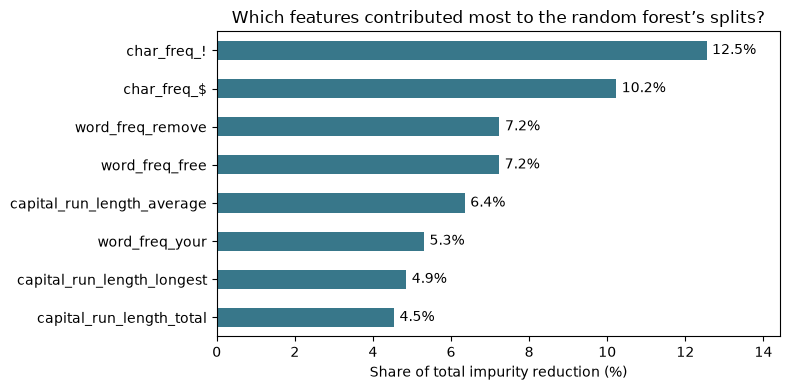

In [14]:
importance = pd.Series(
    final_forest.feature_importances_,
    index=final_forest.feature_names_in_,
    name="Importance"
)

top_features = importance.nlargest(8).mul(100).sort_values()

ax = top_features.plot.barh(figsize=(8, 4), color="#38778a")
ax.set(
    title="Which features contributed most to the random forest’s splits?",
    xlabel="Share of total impurity reduction (%)",
    ylabel=""
)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

### Which features contributed most to the random forest?

Use of exclamation marks was first in the order with 12.5% contribution to overall reduction in impurity of the forest. Use of dollar signs followed closely at 10.2%. Combined, these two features contributed 22.7% to overall improvement in classification separability of the forest. This is consistent with earlier findings that indicated higher use of these two symbols in spam emails compared to regular emails. The forest also had information on frequency of occurrence of these symbols in emails.

The ranking of the features explains the findings from the feature group experiment. Despite the two best-ranking features being related to punctuation, the set of 48 word features performed better (F1 = 0.912) compared to the nine character and capitalization features (F1 = 0.856). There were several words that contributed to the split of the forest, namely “remove” (7.2%), “free” (7.2%), and “your” (5.3%). All three capitalization features were among the eight top-ranking features.

The model with all 57 features gave the highest F1 (0.930) for validation. The graph depicts the role that individual features played in building the fitted forest, while the validation data represents the performance of feature groups on out-of-bag emails. The percentage value of a feature does not reveal how the model will perform after the feature deletion.

## Conclusion

The best spam F1 on average in grouped cross-validation was obtained by the random forest classifier (0.930) and logistic regression (0.891). On the 921 withheld emails, the default decision rule of the random forest classifier resulted in 95.2% accuracy and detected 333 out of 363 spam emails. The majority baseline showed 60.6% accuracy but failed to detect any of them. Identical feature sets were kept to ensure that every test prediction included some combination of features unknown to the model during training.

The most helpful data for classification purposes was the frequency of occurrence of each word in emails. The words-only forest performed better in validation F1 (0.912) than character-based classifiers with capitalization (0.856). Combination of both reduced both types of errors. In validation folds, the full model detected 41 fewer legitimate emails and 13 fewer spam emails than the words-only model.

The criterion for selecting the threshold was based on the kind of error one needed to avoid. The increase of the threshold to 0.75 made sure that the 99.0% spam precision was attained while the number of genuine email wrongly categorized as spam went down from 14 to 3. But at the same time, the number of spam not identified went up from 30 to 67. I would consider using the default threshold when precision and recall need to be balanced out. I would go for the more stringent threshold where missing out on a genuine email is costlier.

## Limitations and Future Work

The Spambase was donated in 1999 and its legitimate emails were derived from the correspondences of the donors. The word “george” for instance, appeared in 25.3% of the legitimate emails used in training while in only 0.6% of the spam. There may be different characteristics of the word frequency of another mailbox. Since the dataset involves numerical characteristics of the emails, it would also be hard to justify a misclassified email by its content.

The next step would then be to check the model using another dataset that is more recent and with independent labeling. Calculation of the same 57 features and the use of both cut-offs before analyzing the labels would verify the trade-off in another mailbox.

## Reference

Hopkins, M., Reeber, E., Forman, G., & Suermondt, J. (1999). *Spambase* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C53G6X